# Tipo de valor gerado — `input_type.png` (Seção 4.2.3)

Mesmo gráfico de `graphic/input/grafico_tipo_input.ipynb`. Os números vêm das colunas *Input value* e *Input consumer* de `../data/tabela_de_codigos_artefatos.csv`: barras por tipo de valor, empilhadas por destino.

In [1]:
import sys
sys.path.insert(0, "../scripts")   # graficos/scripts: dados_artefatos.py, paleta_grupos.py

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import dados_artefatos as da
from paleta_grupos import tons_grupo, CINZA_OUTROS, CINZA_INDEFINIDO

# família verde do grupo input: três tons bem separados (claro, médio, escuro)
cor_humano, cor_determ, cor_llm = tons_grupo("input", 3, inicio=0.05)

In [2]:
def cor_texto_legivel(hex_cor):
    r, g, b = (int(hex_cor[i : i + 2], 16) for i in (1, 3, 5))
    luminancia = 0.299 * r + 0.587 * g + 0.114 * b
    return "black" if luminancia > 150 else "white"

# rótulo de cada código no gráfico
rotulos = {
    "IV1": "Parameter, argument,\nor test data (code)",
    "IV2": "Seed, program, or harness\n(fuzzing, search)",
    "IV3": "Interaction action or\ntext to fill (GUI/mobile)",
    "IV4": "Property value or\nrequest (API/protocol)",
    "IV5": "SQL / database",
    "IV6": "Other (shell command,\nSMT formula, simulator\nscenario...)",
}
# estudos por tipo de valor gerado (linhas) e destino (colunas)
tabela = da.cruzamento("Input value", "Input consumer")
dados = [{"tipo": rotulos[c], "ferramenta": int(tabela.loc[c, "ID1"]), "llm": int(tabela.loc[c, "ID2"]),
          "humano": int(tabela.loc[c, "ID3"])} for c in rotulos]

destinos = [
    ("ferramenta", cor_determ, "Deterministic tool"),
    ("llm", cor_llm, "For LLM"),
    ("humano", cor_humano, "Human"),
]

x_pos = range(len(dados))
totais_dest = {k: sum(d[k] for d in dados) for k, _, _ in destinos}
total = sum(totais_dest.values())
print(totais_dest, "total =", total)
assert total == len(da.estudos("Input value"))

{'ferramenta': 151, 'llm': 16, 'humano': 5} total = 172


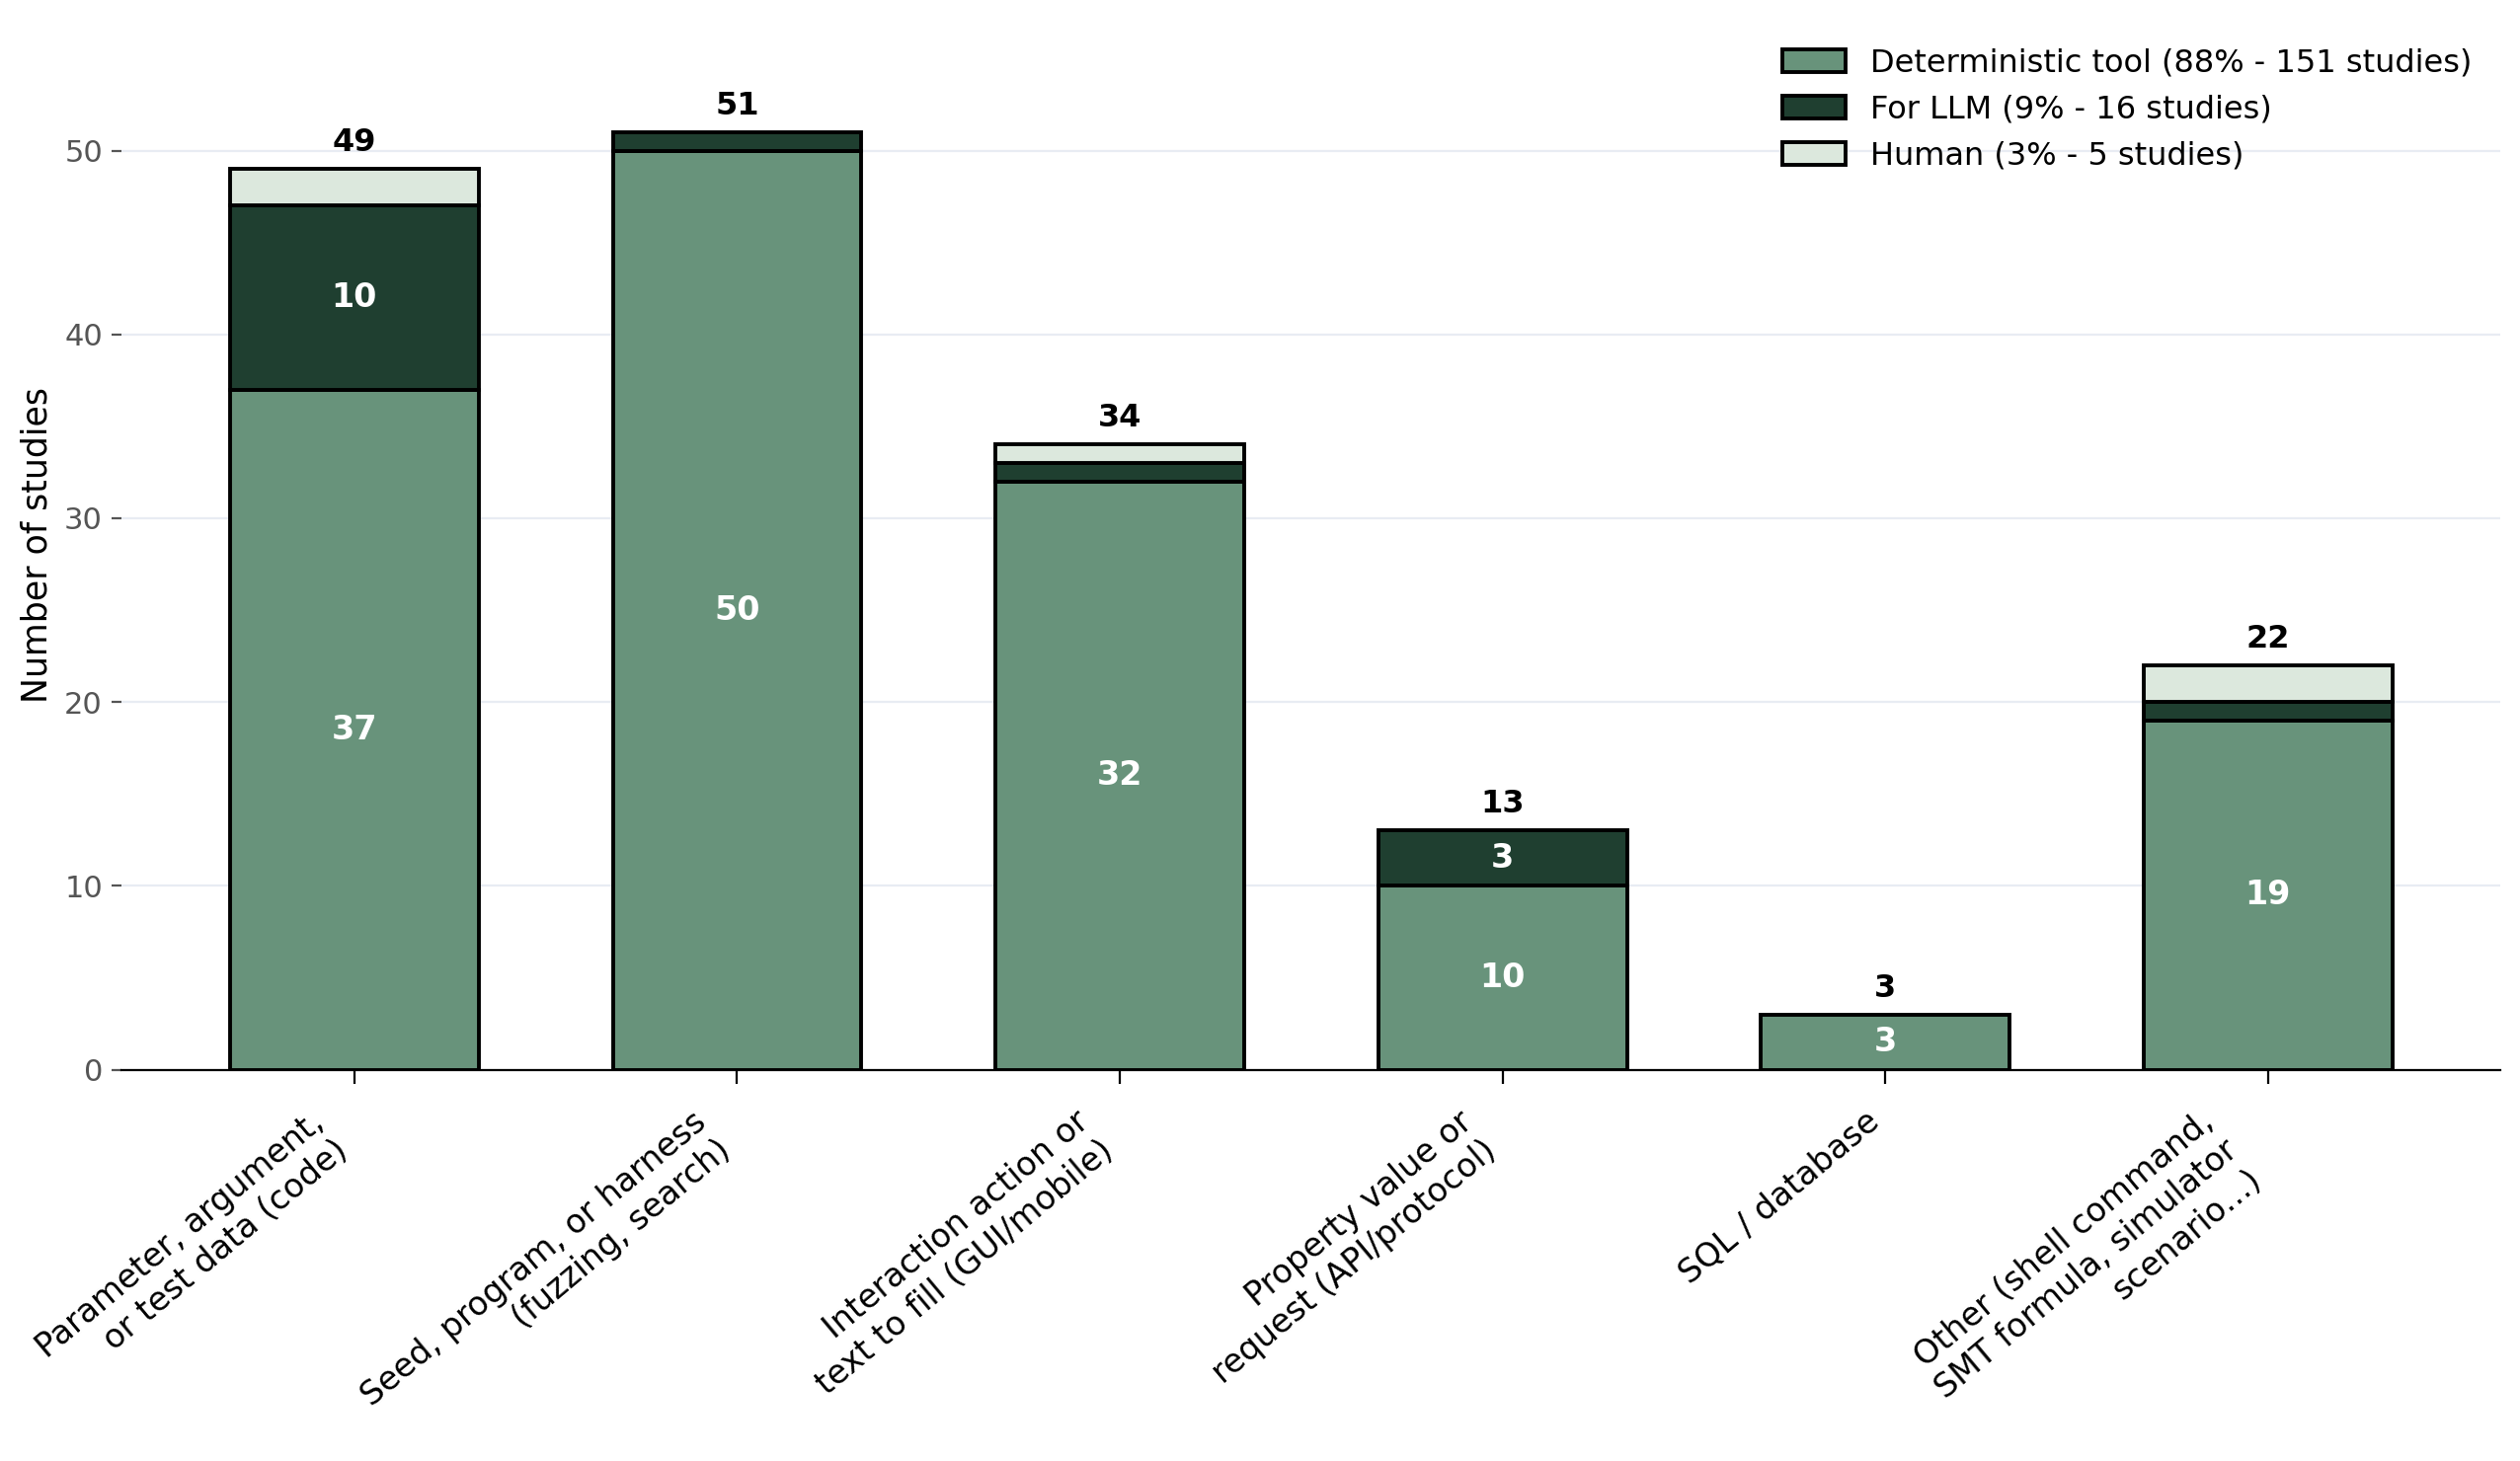

In [3]:
fig, ax = plt.subplots(figsize=(13, 7.5), dpi=200)

for x, d in zip(x_pos, dados):
    base = 0
    for chave, cor, _ in destinos:
        v = d[chave]
        if v == 0:
            continue
        ax.bar(x, v, bottom=base, color=cor, width=0.65, edgecolor="black", linewidth=1.4, zorder=3)
        # número dentro do segmento só quando cabe (segmentos menores que 3 ficam sem rótulo)
        if v >= 3:
            ax.text(x, base + v / 2, str(v), ha="center", va="center", fontsize=12,
                    fontweight="bold", color=cor_texto_legivel(cor), zorder=4)
        base += v
    ax.text(x, base + 0.6, str(base), ha="center", va="bottom", fontsize=11.5,
            fontweight="bold", color="black")

ax.set_xticks(list(x_pos))
ax.set_xticklabels([d["tipo"] for d in dados], rotation=40, ha="right", fontsize=12)

ax.set_ylim(0, max(d["ferramenta"] + d["llm"] + d["humano"] for d in dados) * 1.12)
ax.set_ylabel("Number of studies", fontsize=12.5)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="x", length=5, pad=8, color="black")
ax.tick_params(axis="y", colors="#555555", labelsize=11)
ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor=cor, edgecolor="black", linewidth=1.4,
          label=f"{nome} ({totais_dest[k] / total:.0%} - {totais_dest[k]} studies)")
    for k, cor, nome in destinos
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False, fontsize=11.5)

plt.tight_layout()
plt.savefig("input_type.png", bbox_inches="tight", dpi=200)
plt.savefig("input_type.pdf", bbox_inches="tight")
plt.show()